# Customer Churn Prediction — Model Explainability with SHAP

## 1. Introduction

Step 4 selected and saved a final model. This notebook explains **how that model makes its
predictions**, using SHAP (SHapley Additive exPlanations).

### What this notebook does and does not claim

SHAP decomposes an individual prediction into per-feature contributions that sum exactly to the
model's output. This tells us what the **model** is doing. It does **not** tell us what causes
churn in the real world.

Three distinct claims must be kept separate throughout:

| Claim type | Supported here? | Example wording |
|---|---|---|
| **Observed dataset relationship** | Yes (from Notebook 1 EDA) | "Month-to-month customers churned at a higher rate in this dataset." |
| **Model behaviour** | Yes (this notebook) | "The model places substantial predictive importance on contract type." |
| **Causal claim** | **No** | ~~"Month-to-month contracts cause churn."~~ |

A feature can carry high SHAP importance because it is a genuine driver, because it is a proxy for
something unmeasured, or because it correlates with a true driver. SHAP cannot distinguish these.
Establishing causation would require an experiment (e.g. randomly offering contract upgrades), not
observational data.

### Methodological guarantees

- The already-fitted pipeline is **loaded**, never refit or retrained.
- Preprocessing is used in `transform`-only mode (it was fit on training data in Step 4).
- `y_test` is **never used** — not to select features, tune parameters, or choose anything.
- `X_test` features are used **only post-hoc**, as a sample of realistic inputs to explain a model
  that was already finalised. Since model selection, tuning, and thresholding were all completed
  in Step 4 using training data alone, explaining the finished model on test inputs introduces no
  leakage into any decision.
- All sampling uses `random_state=42`.

## 2. Load Saved Model

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

import data_preprocessing as dp
import evaluate as ev
import explain as ex

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Telco-Customer-Churn.csv"
MODEL_PATH = PROJECT_ROOT / "models" / "churn_model.pkl"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("SHAP version:  ", shap.__version__)
import xgboost, sklearn
print("XGBoost version:", xgboost.__version__)
print("sklearn version:", sklearn.__version__)


SHAP version:   0.52.0
XGBoost version: 3.4.1
sklearn version: 1.8.0


In [2]:
pipeline = ex.load_model(MODEL_PATH)
print("Loaded pipeline from:", MODEL_PATH)
print("Pipeline class:", type(pipeline).__name__)
pipeline


Loaded pipeline from: /path/to/customer-churn-prediction/models/churn_model.pkl
Pipeline class: Pipeline


,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The

## 3. Inspect Pipeline

Before explaining anything we verify the saved artifact is the model Step 4 reported: an XGBoost
classifier, with SMOTE present, 19 original features expanding to 45 transformed features.

Note on SMOTE: it is part of the saved pipeline, but it is a *resampling* step. `imblearn`
pipelines skip resamplers outside of `fit`, so SMOTE plays no role in generating explanations. We
access the `preprocessor` and `classifier` steps directly, so SHAP sees exactly the matrix the
classifier consumes.

In [3]:
info = ex.inspect_pipeline(pipeline)
for k, v in info.items():
    print(f"{k:<28} {v}")


pipeline_class               Pipeline
steps                        {'preprocessor': 'ColumnTransformer', 'smote': 'SMOTE', 'classifier': 'XGBClassifier'}
classifier_type              XGBClassifier
classifier_module            xgboost.sklearn
is_tree_based                True
smote_included               True
n_original_features          19
n_transformed_features       45


In [4]:
# Cross-check against the metadata saved in Step 4
import json
metadata = json.load(open(PROJECT_ROOT / "models" / "model_metadata.json"))

print(f"Step 4 reported model:    {metadata['model_name']}")
print(f"Loaded classifier type:   {info['classifier_type']}")
print(f"Step 4 transformed count: {metadata['n_transformed_features']}")
print(f"Loaded transformed count: {info['n_transformed_features']}")

assert info["classifier_type"] == "XGBClassifier", "Classifier type mismatch!"
assert info["n_transformed_features"] == metadata["n_transformed_features"], "Feature count mismatch!"
print("\nConfirmed: the saved artifact matches the model reported in Step 4.")

print(f"\nHyperparameters from Step 4: {metadata['best_hyperparameters']}")
clf = pipeline.named_steps["classifier"]
print(f"Loaded classifier params:    n_estimators={clf.n_estimators}, max_depth={clf.max_depth}, "
      f"learning_rate={clf.learning_rate}, subsample={clf.subsample}, colsample_bytree={clf.colsample_bytree}")


Step 4 reported model:    XGBoost
Loaded classifier type:   XGBClassifier
Step 4 transformed count: 45
Loaded transformed count: 45

Confirmed: the saved artifact matches the model reported in Step 4.

Hyperparameters from Step 4: {'classifier__subsample': '0.7', 'classifier__n_estimators': '200', 'classifier__max_depth': '4', 'classifier__learning_rate': '0.03', 'classifier__colsample_bytree': '0.8'}
Loaded classifier params:    n_estimators=200, max_depth=4, learning_rate=0.03, subsample=0.7, colsample_bytree=0.8


## 4. Load Data

We reload the raw CSV and reproduce the identical split using the same functions and
`random_state=42`, so the rows we explain are genuinely held-out rows the model never trained on.

In [5]:
raw_df = dp.load_data(RAW_DATA_PATH)
print(f"Raw shape: {raw_df.shape}")
raw_df.head(3)


Raw shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## 5. Reproduce Existing Cleaning / Feature Processing

We call the **same** `dp.clean_data()` and `dp.create_train_test_split()` used in Steps 3 and 4 —
no re-implementation, no redesign.

In [6]:
df_clean = dp.clean_data(raw_df)
X, y = dp.split_features_target(df_clean)
X_train, X_test, y_train, y_test = dp.create_train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
numerical_features, categorical_features = dp.get_feature_types(X_train)

print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"Numerical features:   {len(numerical_features)}")
print(f"Categorical features: {len(categorical_features)}")
print()
print("REMINDER: y_test is loaded only to keep the split function signature intact.")
print("It is NOT used anywhere in this notebook for any decision.")


X_train: (5634, 19)
X_test:  (1409, 19)
Numerical features:   4
Categorical features: 15

REMINDER: y_test is loaded only to keep the split function signature intact.
It is NOT used anywhere in this notebook for any decision.


## 6. Verify Feature Names

Feature names are recovered **programmatically** from the fitted `ColumnTransformer` via
`get_feature_names_out()` — never typed by hand. `customerID` was dropped before modelling so it
cannot appear.

In [7]:
feature_names = ex.get_feature_names(pipeline)

print(f"Original features:    {X_train.shape[1]}")
print(f"Transformed features: {len(feature_names)}")
print()
print("First 12 transformed names:")
for n in feature_names[:12]:
    print(f"  {n}")
print("  ...")

assert "customerID" not in " ".join(feature_names), "customerID leaked into features!"
print("\nConfirmed: customerID is absent from the feature set.")


Original features:    19
Transformed features: 45

First 12 transformed names:
  num__SeniorCitizen
  num__tenure
  num__MonthlyCharges
  num__TotalCharges
  cat__gender_Female
  cat__gender_Male
  cat__Partner_No
  cat__Partner_Yes
  cat__Dependents_No
  cat__Dependents_Yes
  cat__PhoneService_No
  cat__PhoneService_Yes
  ...

Confirmed: customerID is absent from the feature set.


In [8]:
# Mapping from transformed feature -> original business feature
feature_mapping = ex.get_feature_mapping(pipeline, numerical_features, categorical_features)

# Show the Contract expansion as a readability example
feature_mapping[feature_mapping["original_feature"] == "Contract"]


,transformed_feature,original_feature,type,category
36,cat__Contract_Month-to-month,Contract,categorical (one-hot),Month-to-month
37,cat__Contract_One year,Contract,categorical (one-hot),One year
38,cat__Contract_Two year,Contract,categorical (one-hot),Two year


In [9]:
print(f"Mapping covers {len(feature_mapping)} transformed features "
      f"across {feature_mapping['original_feature'].nunique()} original features.")
feature_mapping.head(10)


Mapping covers 45 transformed features across 19 original features.


,transformed_feature,original_feature,type,category
0,num__SeniorCitizen,SeniorCitizen,numerical,NaN
1,num__tenure,tenure,numerical,NaN
2,num__MonthlyCharges,MonthlyCharges,numerical,NaN
3,num__TotalCharges,TotalCharges,numerical,NaN
4,cat__gender_Female,gender,categorical (one-hot),Female
5,cat__gender_Male,gender,categorical (one-hot),Male
6,cat__Partner_No,Partner,categorical (one-hot),No
7,cat__Partner_Yes,Partner,categorical (one-hot),Yes
8,cat__Dependents_No,Dependents,categorical (one-hot),No
9,cat__Dependents_Yes,Dependents,categorical (one-hot),Yes


## 7. Select SHAP Explanation Dataset

**Which rows are explained, and why:** a reproducible random sample of **500 rows from `X_test`**
(`random_state=42`).

Justification:
- `X_test` rows are genuinely unseen by the model, so the explanations describe behaviour on
  realistic new inputs rather than data the model memorised.
- Using test *features* post-hoc is safe here: every modelling decision (algorithm, hyperparameters,
  threshold) was finalised in Step 4 using training data only. Nothing in this notebook feeds back
  into the model.
- `y_test` is not touched.
- 500 rows (of 1,409 available) is ample for stable mean-absolute-SHAP estimates while keeping
  computation quick. TreeExplainer is exact for tree models, so this is a sampling choice about
  *which rows to describe*, not an approximation of the SHAP values themselves.

In [10]:
SAMPLE_SIZE = 500
X_explain = X_test.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE)
X_explain_transformed = ex.transform_features(pipeline, X_explain)

print(f"Rows explained: {X_explain.shape[0]} (sampled from {X_test.shape[0]} test rows)")
print(f"Transformed explanation matrix: {X_explain_transformed.shape}")

assert X_explain_transformed.shape[1] == len(feature_names), "Dimension mismatch!"
print(f"\nDimension check: {X_explain_transformed.shape[1]} columns == {len(feature_names)} names. PASS")


Rows explained: 500 (sampled from 1409 test rows)
Transformed explanation matrix: (500, 45)

Dimension check: 45 columns == 45 names. PASS


## 8. Create SHAP Explainer

The explainer is chosen based on the **actual** classifier type, not assumed. Our saved model is
an `XGBClassifier`, which is tree-based, so `TreeExplainer` is appropriate — it computes exact
Shapley values for tree ensembles efficiently. `src/explain.py` falls back to the model-agnostic
`shap.Explainer` if a non-tree model is ever selected, rather than forcing TreeExplainer onto an
incompatible model.

In [11]:
explainer, explainer_name = ex.create_shap_explainer(pipeline)
print(f"Classifier is tree-based: {info['is_tree_based']}")
print(f"Explainer selected: {explainer_name}")


Classifier is tree-based: True
Explainer selected: TreeExplainer


## 9. Calculate SHAP Values

### What do these values actually represent?

This matters and is easy to get wrong. For a binary XGBoost classifier, `TreeExplainer` returns
values in the model's **raw margin (log-odds)** space — **not** probability. We verify this
empirically rather than assuming it, using SHAP's additivity property:

```
sum(shap_values) + base_value  ==  model output for that row
```

We compare that sum against both the raw margin and the predicted probability to determine which
space we are in.

In [12]:
shap_explanation = ex.calculate_shap_values(explainer, X_explain_transformed, feature_names)

print(f"SHAP values shape:  {shap_explanation.values.shape}")
print(f"Base values shape:  {np.shape(shap_explanation.base_values)}")
print(f"Base value (row 0): {shap_explanation.base_values[0]:.6f}")


SHAP values shape:  (500, 45)
Base values shape:  (500,)
Base value (row 0): 0.000302


In [13]:
additivity = ex.verify_shap_additivity(shap_explanation, pipeline, X_explain_transformed, row=0)

print("Additivity check on row 0:")
print(f"  sum(shap) + base_value : {additivity['shap_sum_plus_base']:.6f}")
print(f"  raw margin (log-odds)  : {additivity['raw_margin']:.6f}")
print(f"  predicted probability  : {additivity['predicted_probability']:.6f}")
print(f"  sigmoid(sum + base)    : {additivity['sigmoid_of_shap_sum']:.6f}")
print()
print(f"  Matches raw margin?  {additivity['matches_raw_margin']}")
print(f"  Matches probability? {additivity['matches_probability']}")
print(f"  sigmoid == probability? {additivity['sigmoid_matches_probability']}")
print()
print(f"  => SHAP OUTPUT SPACE: {additivity['output_space']}")


Additivity check on row 0:
  sum(shap) + base_value : -0.877647
  raw margin (log-odds)  : -0.877647
  predicted probability  : 0.293666
  sigmoid(sum + base)    : 0.293666

  Matches raw margin?  True
  Matches probability? False
  sigmoid == probability? True

  => SHAP OUTPUT SPACE: raw margin (log-odds)


In [14]:
# Verify additivity across ALL explained rows, not just one
clf = pipeline.named_steps["classifier"]
sums = shap_explanation.values.sum(axis=1) + shap_explanation.base_values
margins = clf.predict(X_explain_transformed, output_margin=True)
probas = clf.predict_proba(X_explain_transformed)[:, 1]
sigmoids = 1.0 / (1.0 + np.exp(-sums))

print(f"Across all {len(sums)} rows:")
print(f"  max |sum(shap)+base - raw_margin|      = {np.max(np.abs(sums - margins)):.3e}")
print(f"  max |sigmoid(sum+base) - probability|  = {np.max(np.abs(sigmoids - probas)):.3e}")
assert np.allclose(sums, margins, atol=1e-4), "Additivity violated!"
print("\nAdditivity holds for every explained row.")


Across all 500 rows:
  max |sum(shap)+base - raw_margin|      = 2.146e-06
  max |sigmoid(sum+base) - probability|  = 1.788e-07

Additivity holds for every explained row.


**Interpretation rule for the rest of this notebook:** a SHAP value of `+0.40` means that
feature pushed the model's output **+0.40 in log-odds**, toward the churn class. It does **not**
mean "+40% probability". Because the sigmoid is non-linear, the same log-odds shift translates to
a different probability change depending on where the prediction already sits.

Note also the base value is approximately **0** log-odds (≈ 0.5 probability) rather than the
dataset's 26.5% churn rate. That is expected: SMOTE balanced the training classes, so the model's
"starting point" before any feature evidence is an even split.

## 10. Global Feature Importance

`mean_abs_shap` is the average magnitude of a feature's influence on the model output across the
explained rows — how much the model **relies on** that feature. `mean_shap` records the average
signed direction.

Neither is a causal quantity, and neither makes a feature "best". This is model-level predictive
influence.

In [15]:
importance_df = ex.compute_global_importance(shap_explanation, feature_mapping)
csv_path = ex.save_shap_outputs(importance_df, REPORTS_DIR)
print(f"Saved: {csv_path}")

importance_df.head(15).round(5)


Saved: /path/to/customer-churn-prediction/reports/shap_feature_importance.csv


,feature,mean_abs_shap,mean_shap,original_feature,category
0,cat__Contract_Month-to-month,0.68811,-0.14420,Contract,Month-to-month
1,num__tenure,0.41720,-0.13088,tenure,NaN
2,cat__OnlineSecurity_No,0.32715,-0.10967,OnlineSecurity,No
3,cat__InternetService_Fiber optic,0.21889,-0.06263,InternetService,Fiber optic
4,cat__PaymentMethod_Electronic check,0.21213,-0.08290,PaymentMethod,Electronic check
5,cat__TechSupport_No,0.19463,-0.06341,TechSupport,No
6,num__MonthlyCharges,0.15738,-0.04987,MonthlyCharges,NaN
7,cat__PaperlessBilling_No,0.13613,-0.05802,PaperlessBilling,No
8,cat__Contract_Two year,0.13458,-0.05295,Contract,Two year
9,cat__StreamingMovies_Yes,0.11363,-0.03446,StreamingMovies,Yes


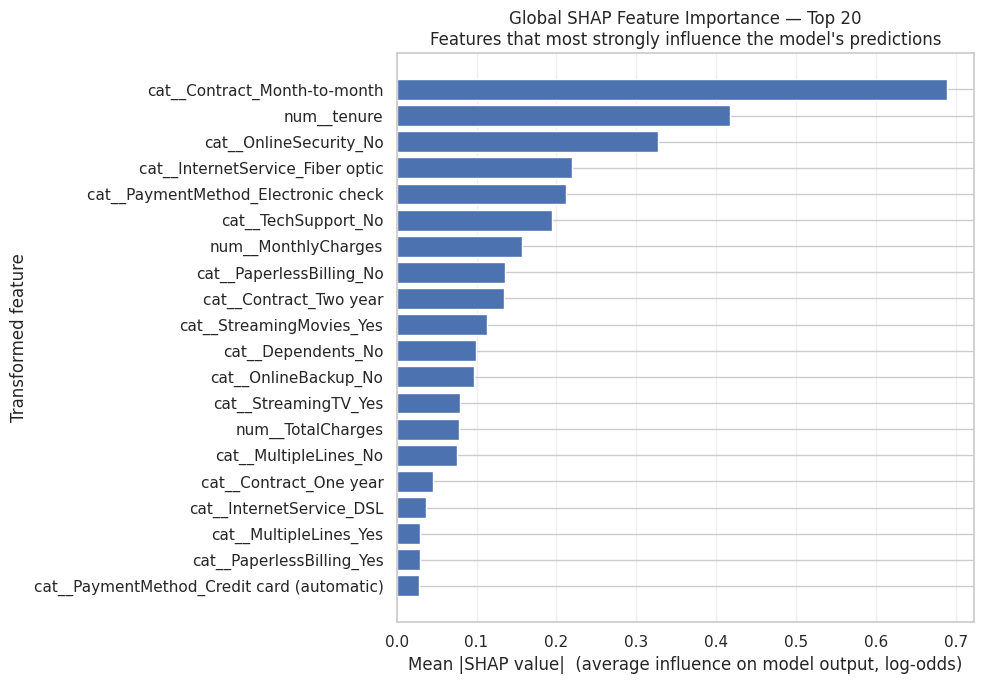

In [16]:
fig = ex.plot_global_feature_importance(
    importance_df, top_n=20, save_path=FIGURES_DIR / "shap_global_importance.png"
)
plt.show()


In [17]:
# Aggregate back to original business features (summing one-hot columns of the same feature)
agg_importance = (
    importance_df.groupby("original_feature", dropna=False)["mean_abs_shap"]
    .sum().sort_values(ascending=False).reset_index()
)
agg_importance.to_csv(REPORTS_DIR / "shap_importance_by_original_feature.csv", index=False)

print("Model influence aggregated by original business feature:")
agg_importance.round(5)


Model influence aggregated by original business feature:


,original_feature,mean_abs_shap
0,Contract,0.86790
1,tenure,0.41720
2,OnlineSecurity,0.33070
3,PaymentMethod,0.26452
4,InternetService,0.25600
5,TechSupport,0.19742
6,PaperlessBilling,0.16478
7,MonthlyCharges,0.15738
8,StreamingMovies,0.12997
9,Dependents,0.10891


## 11. SHAP Beeswarm

The beeswarm shows three things at once: which features matter most (vertical order), the
direction of influence (left/right of zero), and the distribution across customers (spread of
dots). Colour encodes the feature's own value — red high, blue low.

Reading it: for a one-hot column, red = the category is present (value 1), blue = absent (value 0).

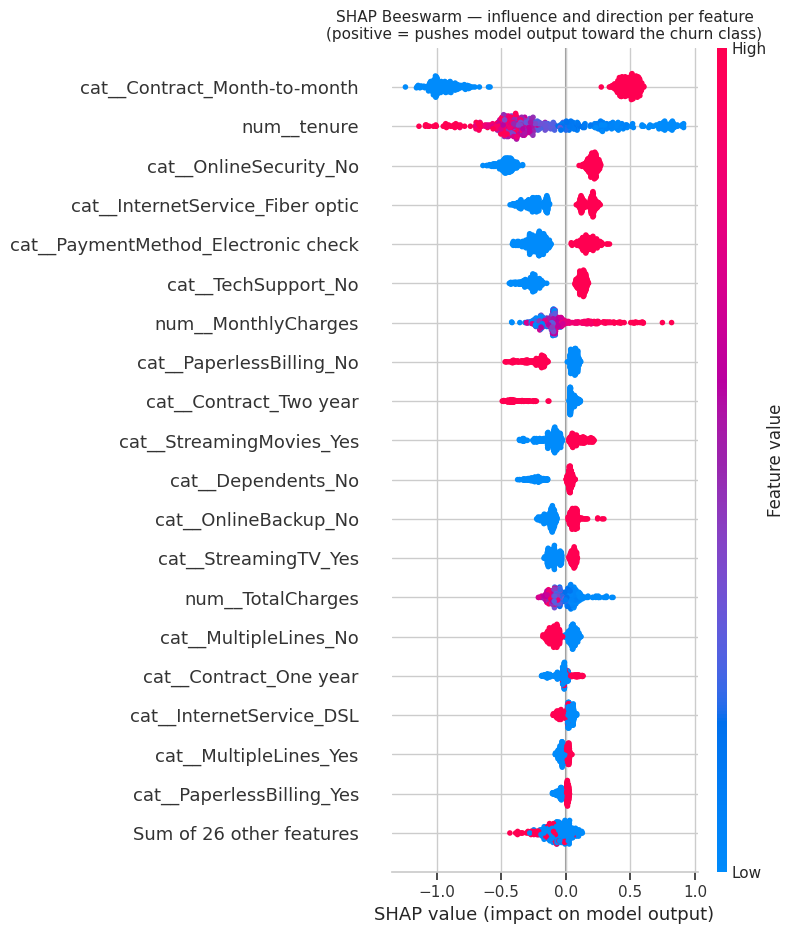

In [18]:
fig = ex.plot_shap_beeswarm(
    shap_explanation, max_display=20, save_path=FIGURES_DIR / "shap_beeswarm.png"
)
plt.show()


## 12. Individual Customer Explanation

We explain a single deterministic example — row 0 of the reproducible sample. The customer is
labelled **"Example Customer"**; `customerID` was dropped before modelling and is never displayed,
so no identifying information is exposed.

In [19]:
individual = ex.explain_individual(
    shap_explanation, pipeline, X_explain, X_explain_transformed, row=0, top_k=8
)

print(f"=== {individual['label']} ===")
print(f"Predicted churn probability: {individual['predicted_probability']:.4f}")
print(f"Predicted class: {individual['predicted_class']} "
      f"({'Churn' if individual['predicted_class'] else 'No churn'}) at threshold 0.50")
print(f"Base value (log-odds): {individual['base_value_log_odds']:.4f}")
print(f"Sum of SHAP values:    {individual['sum_shap_log_odds']:.4f}")


=== Example Customer ===
Predicted churn probability: 0.2937
Predicted class: 0 (No churn) at threshold 0.50
Base value (log-odds): 0.0003
Sum of SHAP values:    -0.8779


In [20]:
print("Input characteristics (no identifying information):")
pd.DataFrame(individual["characteristics"], index=["Example Customer"]).T


Input characteristics (no identifying information):


,Example Customer
gender,Female
SeniorCitizen,0
Partner,Yes
Dependents,No
tenure,9
PhoneService,Yes
MultipleLines,No
InternetService,DSL
OnlineSecurity,No
OnlineBackup,Yes


In [21]:
print("Top contributors PUSHING the prediction TOWARD churn (positive SHAP, log-odds):")
individual["top_positive_contributors"][["feature", "shap_value"]].round(5)


Top contributors PUSHING the prediction TOWARD churn (positive SHAP, log-odds):


,feature,shap_value
0,cat__Contract_Month-to-month,0.42049
1,cat__OnlineSecurity_No,0.15546
2,cat__TechSupport_No,0.08031
3,cat__StreamingTV_No,0.04853
4,num__tenure,0.04242
5,cat__Contract_Two year,0.04148
6,cat__StreamingMovies_No,0.03869
7,num__TotalCharges,0.03507


In [22]:
print("Top contributors PUSHING the prediction AWAY FROM churn (negative SHAP, log-odds):")
individual["top_negative_contributors"][["feature", "shap_value"]].round(5)


Top contributors PUSHING the prediction AWAY FROM churn (negative SHAP, log-odds):


,feature,shap_value
0,cat__InternetService_Fiber optic,-0.34773
1,cat__PaperlessBilling_No,-0.30503
2,cat__PaymentMethod_Electronic check,-0.25201
3,cat__OnlineBackup_No,-0.13188
4,cat__StreamingTV_Yes,-0.11279
5,cat__MultipleLines_No,-0.10392
6,cat__StreamingMovies_Yes,-0.08810
7,num__MonthlyCharges,-0.08168


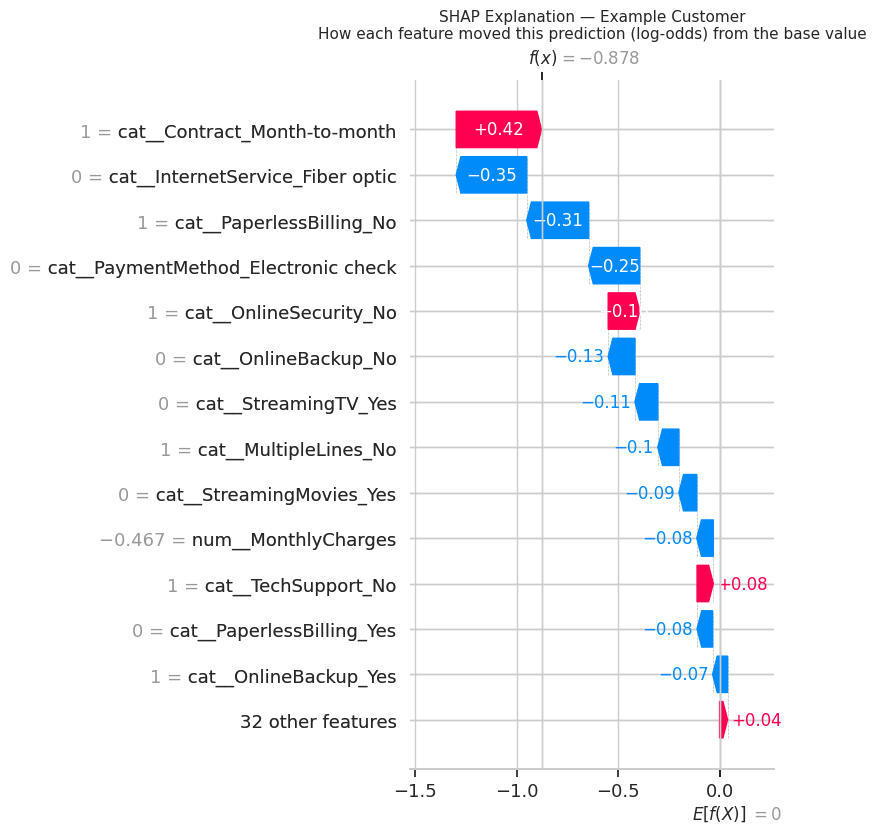

In [23]:
fig = ex.plot_individual_explanation(
    shap_explanation, row=0, max_display=14,
    save_path=FIGURES_DIR / "shap_individual_example.png"
)
plt.show()


In [24]:
# Verify this individual explanation reconciles with the saved pipeline's own prediction
pipeline_proba_row0 = pipeline.predict_proba(X_explain.iloc[[0]])[:, 1][0]
print(f"Pipeline predict_proba:      {pipeline_proba_row0:.6f}")
print(f"Explanation-path probability: {individual['predicted_probability']:.6f}")
assert np.isclose(pipeline_proba_row0, individual["predicted_probability"], atol=1e-6)
print("\nConfirmed: the explanation path reproduces the saved pipeline's prediction exactly.")


Pipeline predict_proba:      0.293666
Explanation-path probability: 0.293666

Confirmed: the explanation path reproduces the saved pipeline's prediction exactly.


## 13. Business Interpretation

*(Read the computed tables and plots above for the actual values; the framing below explains how
to interpret them correctly.)*

**How to read a SHAP value here.** High positive SHAP values indicate features that push a
particular prediction toward the churn class; negative values push it away. The values are in
log-odds, so they are additive on that scale and sum, with the base value, to the model's raw
output for that customer.

**What the global importance table tells us.** It ranks features by how much the model's output
moves when that feature is present/varies — i.e. how heavily the model **relies** on each feature.
Phrase findings as, for example: *"The model places substantial predictive importance on contract
type"* or *"tenure strongly influences the model's predictions."*

**What it does not tell us.** It does not establish that changing a feature would change a
customer's real churn behaviour. Some concrete reasons to stay cautious:
- **Proxy effects.** A feature may stand in for something unmeasured (e.g. price sensitivity,
  service quality in a region, customer segment).
- **Correlated features.** When features move together, SHAP distributes credit among them; a
  slightly different but equally valid model could split that credit differently.
- **Encoding artefacts.** One-hot columns split a single business concept across several columns.
  The aggregated table in Section 10 is the fairer view of a categorical feature's total influence.
- **Direction ≠ intervention.** "Feature X pushes predictions toward churn" describes the model's
  learned association, not the effect of an intervention on X.

**How a retention team could legitimately use this.** As a *triage and explanation* aid: the model
ranks who to contact, and SHAP indicates which factors drove each flag, giving the agent context
for the conversation. Deciding which retention action actually *works* requires a controlled
experiment (e.g. randomised offers), which is outside this project's scope.

**Keeping the three claim types separate:**
1. *Observed dataset relationship* (Notebook 1, EDA) — descriptive statistics of who churned.
2. *Model behaviour* (this notebook) — what the fitted model relies on.
3. *Causal claim* — **not supported by this project.**

## 14. Limitations

**Of SHAP interpretation specifically:**
- SHAP explains the model, not the data-generating process. A model can be wrong and SHAP will
  faithfully explain the wrong model.
- Values are in log-odds, not probability; the same SHAP magnitude implies different probability
  changes depending on the prediction's starting point.
- TreeExplainer's default (interventional/path-dependent) handling of correlated features means
  credit allocation among correlated predictors is not unique.
- Explanations describe 500 sampled test rows; a different sample would shift values slightly
  (though TreeExplainer itself is exact per row).
- The base value reflects SMOTE-balanced training (≈0.5), not the real-world 26.5% churn rate, so
  base-value intuitions must account for that.

**Inherited from earlier steps:**
- The three candidate models were statistically indistinguishable on CV ROC-AUC (XGBoost's lead
  was smaller than its own fold-to-fold standard deviation), so explanations are of *a*
  defensible model, not a uniquely correct one. A Logistic Regression would give a different,
  also-defensible importance picture.
- Static single-snapshot dataset with no time dimension.
- A public benchmark dataset, not any specific business's customers.

## 15. Summary

This notebook loaded the Step 4 pipeline without modifying it, verified it matches the reported
XGBoost model (19 → 45 features, SMOTE present), recovered transformed feature names
programmatically, explained a reproducible 500-row sample of held-out test features with
`TreeExplainer`, **empirically verified** that the SHAP values live in log-odds space (and that
their sum reconstructs the model output for every row), produced global importance, beeswarm, and
individual waterfall artifacts, and confirmed the explanation path reproduces the saved pipeline's
predictions exactly.

Throughout, results are described as **model-level predictive influence**, never as causation, and
never as a "best feature" ranking.